<a href="https://colab.research.google.com/github/Permurez/Heartbeat/blob/main/notebooks/01_ground_truth_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
#SETUP: run this first after every runtime restart
from google.colab import drive
drive.mount('/content/drive')

import zipfile
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline

ZIP_PATH = '/content/drive/MyDrive/Datasets_rPPG/ubfc_rppg.zip'
LOCAL_DIR = '/content/ubfc'

def load_ground_truth(subject):
    """Read UBFC-rPPG ground truth: returns (ppg, hr, t) as numpy arrays."""
    with zipfile.ZipFile(ZIP_PATH) as zf:
        text = zf.read(f'{subject}/ground_truth.txt').decode()
    ppg, hr, t = (np.array(line.split(), dtype=float) for line in text.strip().splitlines())
    return ppg, hr, t

ppg, hr, t = load_ground_truth('subject1')
print(f"Loaded subject1: {len(t)} samples, {t[-1]:.1f} s")

Mounted at /content/drive
Loaded subject1: 1547 samples, 52.7 s


In [ ]:
import os
from google.colab import drive
from google.colab import userdata
# 1. Montowanie Dysku Google
drive.mount('/content/drive')

# Utworzenie folderu docelowego na Dysku Google
DRIVE_DEST_DIR = '/content/drive/MyDrive/Datasets_rPPG'
os.makedirs(DRIVE_DEST_DIR, exist_ok=True)

# Konfiguracja uwierzytelniania Kaggle przez zmienne środowiskowe
# (API Kaggle akceptuje token w zmiennej KAGGLE_KEY, czasem wymagany jest też dummy username)
os.environ['KAGGLE_USERNAME'] = 'Bearer'
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_API_TOKEN')

# 2. Instalacja biblioteki Kaggle
!pip install kaggle

# 3. Pobieranie datasetu przez API Kaggle
DATASET_NAME = 'malekdinarito/ubfc-rppg-dataset'
DOWNLOAD_DIR = '/content/kaggle_temp'

os.makedirs(DOWNLOAD_DIR, exist_ok=True)
os.chdir(DOWNLOAD_DIR)

print(f"Pobieram dataset {DATASET_NAME} bezpośrednio na serwery Google...")
!kaggle datasets download -d {DATASET_NAME}

# 4. Przeniesienie i spakowanie pliku bezpośrednio na Dysk Google
import glob

zip_files = glob.glob('*.zip')
if zip_files:
    downloaded_zip = zip_files[0]
    dest_path = os.path.join(DRIVE_DEST_DIR, 'ubfc_rppg.zip')

    print(f"Kopiuję plik na Dysk Google do: {dest_path}")
    !cp "{downloaded_zip}" "{dest_path}"
    print("Sukces! Dataset został pobrany i zapisany bezpośrednio na Twoim Dysku Google.")
else:
    print("Błąd podczas pobierania. Sprawdź poprawność tokenu.")

Mounted at /content/drive
Pobieram dataset malekdinarito/ubfc-rppg-dataset bezpośrednio na serwery Google...
Dataset URL: https://www.kaggle.com/datasets/malekdinarito/ubfc-rppg-dataset
License(s): CC0-1.0
100% 31.2G/31.2G [06:19<00:00, 88.3MB/s]

Kopiuję plik na Dysk Google do: /content/drive/MyDrive/Datasets_rPPG/ubfc_rppg.zip
Sukces! Dataset został pobrany i zapisany bezpośrednio na Twoim Dysku Google.


In [ ]:
!ls -lh /content/drive/MyDrive/Datasets_rPPG/

total 32G
-rw------- 1 root root 32G Oct 26 10:25 ubfc_rppg.zip


In [6]:
from google.colab import drive
drive.mount('/content/drive')

import zipfile, collections

ZIP_PATH = '/content/drive/MyDrive/Datasets_rPPG/ubfc_rppg.zip'

with zipfile.ZipFile(ZIP_PATH) as zf:
    infos = zf.infolist()
    print(f"Entries: {len(infos)}")
    for info in infos[:40]:
        print(f"{info.file_size/1e6:10.1f} MB  {info.filename}")
    top = collections.Counter(i.filename.split('/')[0] for i in infos)
    print("Top-level folders:", top)

Mounted at /content/drive
Entries: 84
       0.1 MB  subject1/ground_truth.txt
    1425.8 MB  subject1/vid.avi
       0.1 MB  subject10/ground_truth.txt
    1865.4 MB  subject10/vid.avi
       0.1 MB  subject11/ground_truth.txt
    1871.9 MB  subject11/vid.avi
       0.1 MB  subject12/ground_truth.txt
    1833.2 MB  subject12/vid.avi
       0.1 MB  subject13/ground_truth.txt
    1859.9 MB  subject13/vid.avi
       0.1 MB  subject14/ground_truth.txt
    1836.9 MB  subject14/vid.avi
       0.1 MB  subject15/ground_truth.txt
    1861.8 MB  subject15/vid.avi
       0.1 MB  subject16/ground_truth.txt
    1889.4 MB  subject16/vid.avi
       0.1 MB  subject17/ground_truth.txt
    1885.7 MB  subject17/vid.avi
       0.1 MB  subject18/ground_truth.txt
    1874.7 MB  subject18/vid.avi
       0.1 MB  subject20/ground_truth.txt
    1858.1 MB  subject20/vid.avi
       0.1 MB  subject22/ground_truth.txt
    1872.8 MB  subject22/vid.avi
       0.1 MB  subject23/ground_truth.txt
    1804.6 MB  subject

In [7]:
import numpy as np
import cv2

SUBJECT = 'subject1'
LOCAL_DIR = '/content/ubfc'

with zipfile.ZipFile(ZIP_PATH) as zf:
    gt_text = zf.read(f'{SUBJECT}/ground_truth.txt').decode()
    zf.extract(f'{SUBJECT}/vid.avi', LOCAL_DIR)

# Ground truth: one row per signal
rows = [np.array(line.split(), dtype=float) for line in gt_text.strip().splitlines()]
print(f"GT rows: {len(rows)}")
for i, row in enumerate(rows):
    print(f"row {i}: {len(row)} values, first: {row[:4]}, min={row.min():.3f}, max={row.max():.3f}")

# Video properties
cap = cv2.VideoCapture(f'{LOCAL_DIR}/{SUBJECT}/vid.avi')
print("FPS:", cap.get(cv2.CAP_PROP_FPS))
print("Frames:", int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))
print("Size:", int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), "x", int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))
cap.release()

GT rows: 3
row 0: 1547 values, first: [0.12028675 0.77360657 1.4119226  1.5395677 ], min=-1.705, max=2.783
row 1: 1547 values, first: [97. 97. 97. 97.], min=97.000, max=113.000
row 2: 1547 values, first: [0.    0.011 0.055 0.067], min=0.000, max=52.691
FPS: 29.264106
Frames: 1547
Size: 640 x 480


Wykresy podglądowe do tętna z obrazu ubfc_rppg

Duration: 52.69 s, mean fs: 29.34 Hz
Frame interval [ms]: mean=34.1, min=0.0, max=223.0, std=11.0


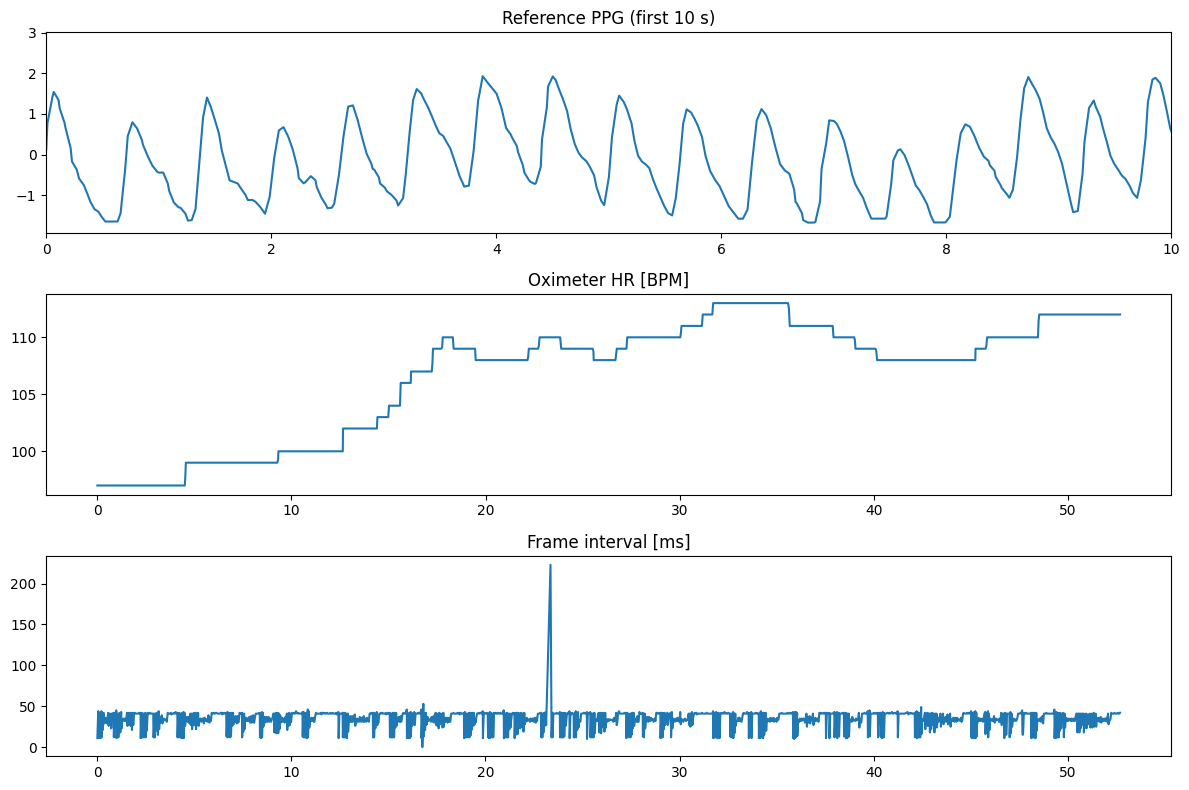

In [8]:
import matplotlib.pyplot as plt

ppg, hr, t = rows
dt_ms = np.diff(t) * 1000

print(f"Duration: {t[-1]:.2f} s, mean fs: {1000/dt_ms.mean():.2f} Hz")
print(f"Frame interval [ms]: mean={dt_ms.mean():.1f}, min={dt_ms.min():.1f}, max={dt_ms.max():.1f}, std={dt_ms.std():.1f}")

fig, ax = plt.subplots(3, 1, figsize=(12, 8))
ax[0].plot(t, ppg); ax[0].set_xlim(0, 10); ax[0].set_title("Reference PPG (first 10 s)")
ax[1].plot(t, hr); ax[1].set_title("Oximeter HR [BPM]")
ax[2].plot(t[1:], dt_ms); ax[2].set_title("Frame interval [ms]")
plt.tight_layout(); plt.show()

1. **Reference PPG** – the pulse oximeter measures how much light passes through the fingertip. Each heartbeat pumps more blood into the finger, so every peak of the wave is one heartbeat. Counting peaks in a time window gives the heart rate.
2. **Oximeter HR [BPM]** – heart rate computed by the oximeter itself (integer values, smoothed). Here it rises from 97 to 113 BPM during the recording.
3. **Frame interval [ms]** – time between consecutive video frames. Ideally a flat line at ~ 33 ms (30 FPS). In reality intervals vary (~15–45 ms) and there is one gap of ~220 ms at ~23 s (dropped frames).
Conclusion: frames are not evenlty spacesd, so the signal must be resampled to a uniform time grid (using timestamps) before filtering and FFT

In [4]:
from scipy.interpolate import CubicSpline

FS = 30.0  # target sampling rate [Hz]

assert np.all(np.diff(t) > 0), "Timestamps must be strictly increasing"

t_uniform = np.arange(t[0], t[-1], 1 / FS)
ppg_linear = np.interp(t_uniform, t, ppg)
ppg_spline = CubicSpline(t, ppg)(t_uniform)

print(f"Original samples: {len(t)}, uniform samples: {len(t_uniform)}")
print(f"Uniform interval std: {np.diff(t_uniform).std()*1000:.6f} ms")

# Zoom on the ~220 ms gap around 23 s
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(t, ppg, 'ko', label='original samples')
ax.plot(t_uniform, ppg_linear, 'b.-', label='linear')
ax.plot(t_uniform, ppg_spline, 'r.-', label='cubic spline')
ax.set_xlim(22.5, 24.5)
ax.legend(); ax.set_xlabel('time [s]'); ax.set_title('Resampling around the frame gap')
plt.show()

AssertionError: Timestamps must be strictly increasing

In [7]:
def clean_timestamps(t, x):
    """Sanitize irregular samples: drop NaNs, sort by time, merge duplicate timestamps.
    x can be 1D (N,) or 2D (N, C), e.g. RGB traces. Returns (t, x, report)."""
    t = np.asarray(t, dtype=float)
    x = np.asarray(x, dtype=float)
    x2d = x.reshape(len(t), -1)                      # treat 1D as a single column
    report = {}

    ok = np.isfinite(t) & np.all(np.isfinite(x2d), axis=1)
    report['nan_dropped'] = int((~ok).sum())
    t, x2d = t[ok], x2d[ok]

    report['backward_steps'] = int((np.diff(t) < 0).sum())
    order = np.argsort(t, kind='stable')
    t, x2d = t[order], x2d[order]

    t_unique, inverse, counts = np.unique(t, return_inverse=True, return_counts=True)
    report['duplicates_merged'] = int(len(t) - len(t_unique))
    x_unique = np.stack([np.bincount(inverse, weights=col) / counts for col in x2d.T], axis=1)

    if x.ndim == 1:
        x_unique = x_unique[:, 0]
    return t_unique, x_unique, report


def resample_uniform(t, x, fs=30.0, method='spline', max_gap=0.1):
    """Clean timestamps, then resample onto a uniform grid at fs Hz.
    Returns (t_new, x_new, valid, report); valid[i] is False where t_new[i]
    lies inside a gap longer than max_gap seconds (interpolated, not measured)."""
    t_c, x_c, report = clean_timestamps(t, x)

    t_new = np.arange(t_c[0], t_c[-1], 1 / fs)
    if method == 'spline':
        x_new = CubicSpline(t_c, x_c, axis=0)(t_new)
    else:
        x_new = np.stack([np.interp(t_new, t_c, col) for col in x_c.reshape(len(t_c), -1).T], axis=1)
        if x_c.ndim == 1:
            x_new = x_new[:, 0]

    gaps = np.diff(t_c)
    big = np.where(gaps > max_gap)[0]
    valid = np.ones(len(t_new), dtype=bool)
    for i in big:
        valid[(t_new > t_c[i]) & (t_new < t_c[i + 1])] = False

    report['gaps_over_max'] = len(big)
    report['largest_gap_ms'] = round(float(gaps.max()) * 1000, 1)
    report['invalid_fraction'] = round(float((~valid).mean()), 4)
    return t_new, x_new, valid, report

In [8]:
import pandas as pd

with zipfile.ZipFile(ZIP_PATH) as zf:
    subjects = sorted({n.split('/')[0] for n in zf.namelist()}, key=lambda s: int(s[7:]))

rows_report = []
for s in subjects:
    ppg_s, hr_s, t_s = load_ground_truth(s)
    _, _, _, rep = resample_uniform(t_s, ppg_s)
    rep['subject'] = s
    rep['duration_s'] = round(t_s[-1], 1)
    rows_report.append(rep)

df = pd.DataFrame(rows_report).set_index('subject')
print(df.to_string())
print("\nTotals:\n", df.sum(numeric_only=True))

           nan_dropped  backward_steps  duplicates_merged  gaps_over_max  largest_gap_ms  invalid_fraction  duration_s
subject                                                                                                               
subject1             0               0                  1              1           223.0            0.0044        52.7
subject3             0               0                  0              5           239.0            0.0153        60.9
subject4             0               0                  1              2           157.0            0.0058        46.2
subject5             0               0                  1              2           152.0            0.0045        52.4
subject8             0               0                  0              3           161.0            0.0059        67.6
subject9             0               0                  1              3           746.0            0.0146        68.3
subject10            0               0          